# 01 — Boosting Model Data Preparation

## Objective

Prepare the regional weekly HAB dataset for training a boosting model.

**Dataset:** `model_table_weekly_fe_reduced.parquet`


### Target
- Class 0: < 5,000 cells/L
- Class 1: 5,000–99,999 cells/L
- Class 2: >= 100,000 cells/L

### Time Split
- Train: target years through 2023
- Validation: 2024
- Test: 2025
- Holdout: 2026

This notebook handles data verification, feature selection, missing values,
class distribution, and creation of the train/validation/test datasets.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
data_path = "/Users/mohammedchowdhury/Desktop/BTT/AI_BTT copy/Biointerphase-1B-copy/data/final/model_table_weekly_fe_reduced.parquet" 

# Load the dataset
df = pd.read_parquet(data_path)

# Create a working copy for feature engineering
df_fe = df.copy()

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset location:", data_path)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

# Preview the first five rows
display(df.head())



Dataset loaded successfully!
Dataset location: /Users/mohammedchowdhury/Desktop/BTT/AI_BTT copy/Biointerphase-1B-copy/data/final/model_table_weekly_fe_reduced.parquet
Number of rows: 595
Number of columns: 104


,week_start,target_week,target_year,bloom_season,split,y_class,y_binary,y_log_cells,y_n_samples,y_n_sites,label_effort_ok,y_class_10k,y_class_box,y_class_mote_25km,n_habsos_samples,n_habsos_days,hab_pos_share,hab_bloom_share,hab_detect_share,hab_log_cells_p90,last_class,last_log_cells,weeks_since_obs,class_max_4wk,log_cells_trend,nutr_bay_chla_corr_ugL_anom,nutr_bay_cond_umho_anom,nutr_bay_do_mgL_anom,nutr_bay_nox_mgL_anom,nutr_bay_po4_mgL_anom,nutr_bay_tn_mgL_anom,nutr_bay_tp_mgL_anom,nutr_bay_water_temp_c_anom,nutr_fresh_chla_corr_ugL_anom,nutr_fresh_cond_umho_anom,nutr_fresh_do_mgL_anom,nutr_fresh_nh3_mgL_anom,nutr_fresh_nox_mgL_anom,nutr_fresh_po4_mgL_anom,nutr_fresh_tkn_mgL_anom,nutr_fresh_tn_mgL_anom,nutr_fresh_tp_mgL_anom,nutr_fresh_water_temp_c_anom,nutr_tidal_chla_corr_ugL_anom,nutr_tidal_cond_umho_anom,nutr_tidal_do_mgL_anom,nutr_tidal_nh3_mgL_anom,nutr_tidal_nox_mgL_anom,nutr_tidal_po4_mgL_anom,nutr_tidal_tkn_mgL_anom,nutr_tidal_tn_mgL_anom,nutr_tidal_tp_mgL_anom,nutr_tidal_water_temp_c_anom,nutr_bay_n_stations,nutr_fresh_n_stations,nutr_tidal_n_stations,nutr_age_weeks,rain_total_mm,rain_days,air_tmean_c,air_trange_c,ksrq_pressure_hpa,ksrq_wind_speed,ksrq_wind_v,has_ksrq,uwnd_box,uwnd_onshore_days,uwnd_westerly_mean,uwnd_easterly_mean,has_mote,chl_box_med,chl_coast20_med,chl_focus_0_10_med,chl_focus_10_40_med,chl_box_n_valid,chl_coast20_anom,chl_focus_0_10_anom,chl_focus_0_40_anom,chl_focus_frac_gt3,chl_focus_frac_gt10,chl_qc_box_cover,rain_2wk_mm,rain_4wk_mm,rain_8wk_mm,uwnd_box_4wk,chl_focus_0_40_anom_4wk,chl_focus_0_10_med_4wk,chl_focus_10_40_med_4wk,chl_focus_0_40_med_chg,last_class_prev,class_change_1wk,last_log_cells_chg1,class_run_weeks,weeks_since_pos,weeks_since_bloom,pos_weeks_12wk,season_sin,season_cos,month,season_week,air_tmean_4wk,air_tmean_anom,air_tmean_chg_1wk,uwnd_box_8wk
0,2015-01-05,2015-01-12,2015,2014,train,0.0,0.0,0.0,29.0,23.0,1,0.0,0.0,0.0,35.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,0.147409,-0.003831,-0.048837,-0.040026,-0.090067,0.185287,-0.158867,3.501512,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.004439,-0.089638,NaN,0.002338,0.104062,0.169605,0.168584,-0.010979,3.571379,30.0,0.0,10.0,0.0,0.000,0.0,15.436508,10.555556,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,0.0,0.068755,0.997634,1,22.0,NaN,-1.897959,NaN,NaN
1,2015-01-12,2015-01-19,2015,2014,train,0.0,0.0,0.0,42.0,36.0,1,0.0,0.0,0.0,29.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,NaN,0.147409,-0.003831,-0.048837,-0.040026,-0.090067,0.185287,-0.158867,3.501512,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.004439,-0.089638,NaN,0.002338,0.104062,0.169605,0.168584,-0.010979,3.571379,0.0,0.0,0.0,1.0,8.636,1.0,17.301587,8.888889,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.636,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,2.0,NaN,NaN,0.0,0.188099,0.982150,1,23.0,NaN,0.869992,1.865079,NaN
2,2015-01-19,2015-01-26,2015,2014,train,0.0,0.0,0.0,33.0,26.0,1,0.0,0.0,0.0,42.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0,0.147409,-0.003831,-0.048837,-0.040026,-0.090067,0.185287,-0.158867,3.501512,-0.004154,0.088848,-0.082732,-0.270426,0.140403,0.172478,0.014827,0.032515,0.068805,-0.030660,0.078249,0.143224,-0.010227,-0.211535,0.203963,0.065072,0.052314,0.053991,0.031591,0.897214,0.0,20.0,9.0,0.0,59.436,2.0,17.658730,11.507937,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68.072,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,3.0,NaN,NaN,0.0,0.304719,0.952442,1,24.0,16.798942,0.738473,0.357143,NaN
3,2015-01-26,2015-02-02,2015,2014,train,0.0,0.0,0.0,71.0,65.0,1,0.0,0.0,0.0,33.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0,0.147409,-0.003831,-0.048837,-0.040026,-0.090067,0.185287,-0.158867,3.501512,-0.095957,-0.032097,-0.118392,0.011921,0.076042,0.196484,0.050216,0.022397,0.075716,0.928334,0.072324,-0.108068,-0.019858,-0.098245,-0.258815,0.187771,0.039312,0.005644,0.129043,0.571572,0.0,14.0,8.0,0.0,0.508,1.0,14.761905,11.904762,NaN,NaN,NaN

In [3]:
print("Dataset shape:", df.shape)

print("\nPredictor week range:")
print("First week:", df["week_start"].min())
print("Last week:", df["week_start"].max())

print("\nImportant columns present:")

important_columns = [
    "week_start",
    "target_week",
    "target_year",
    "split",
    "y_class"
]

for column in important_columns:
    print(column, "->", column in df.columns)

Dataset shape: (595, 104)

Predictor week range:
First week: 2015-01-05 00:00:00
Last week: 2026-05-25 00:00:00

Important columns present:
week_start -> True
target_week -> True
target_year -> True
split -> True
y_class -> True


In [4]:
print("Total weeks:", len(df))

print(
    "Weeks with known y_class:",
    df["y_class"].notna().sum()
)

print(
    "Weeks with missing y_class:",
    df["y_class"].isna().sum()
)

Total weeks: 595
Weeks with known y_class: 486
Weeks with missing y_class: 109


In [5]:
print("All rows by split:")
print(df["split"].value_counts())

print("\nLabeled rows by split:")
print(
    df[df["y_class"].notna()]
    ["split"]
    .value_counts()
)

All rows by split:
split
train       468
validate     53
test         52
holdout      22
Name: count, dtype: int64

Labeled rows by split:
split
train       364
validate     52
test         52
holdout      18
Name: count, dtype: int64


In [6]:
print("Overall class distribution:")

print(
    df.loc[df["y_class"].notna(), "y_class"]
    .value_counts()
    .sort_index()
)

print("\nClass distribution by split:")

print(
    pd.crosstab(
        df.loc[df["y_class"].notna(), "split"],
        df.loc[df["y_class"].notna(), "y_class"]
    )
)

Overall class distribution:
y_class
0.0    286
1.0     65
2.0    135
Name: count, dtype: int64

Class distribution by split:
y_class   0.0  1.0  2.0
split                  
holdout    18    0    0
test       45    1    6
train     185   59  120
validate   38    5    9


## 2. Feature Selection

We begin with the `regional_core` feature set defined in the October
feature-engineering pipeline.

This gives the boosting model a controlled set of HAB history,
duration, sampling, and seasonal predictors before testing additional
environmental feature groups.

In [7]:
# Regional core features defined in notebook 05

regional_core = [
    "last_class",
    "last_log_cells",
    "last_class_prev",
    "last_log_cells_chg1",
    "weeks_since_obs",
    "class_max_4wk",
    "n_habsos_samples",
    "weeks_since_bloom",
    "pos_weeks_12wk",
    "class_run_weeks",
    "season_sin",
    "season_cos"
]

print("Number of selected features:", len(regional_core))

for feature in regional_core:
    print(feature)

Number of selected features: 12
last_class
last_log_cells
last_class_prev
last_log_cells_chg1
weeks_since_obs
class_max_4wk
n_habsos_samples
weeks_since_bloom
pos_weeks_12wk
class_run_weeks
season_sin
season_cos


In [8]:
missing_features = [
    feature
    for feature in regional_core
    if feature not in df.columns
]

if missing_features:
    print("Missing features:", missing_features)
else:
    print("All regional_core features are present!")

All regional_core features are present!


In [9]:
forbidden_columns = [
    "y_class",
    "y_binary",
    "y_log_cells",
    "y_n_samples",
    "y_n_sites",
    "label_effort_ok",
    "y_class_10k",
    "y_class_box",
    "y_class_mote_25km",
    "target_week",
    "target_year",
    "bloom_season",
    "split"
]

leakage_found = [
    column
    for column in regional_core
    if column in forbidden_columns
]

if leakage_found:
    print("WARNING — possible leakage:", leakage_found)
else:
    print("No forbidden target columns found in regional_core.")

No forbidden target columns found in regional_core.


### Create the labeled modeling dataset

In [10]:
model_df = df[df["y_class"].notna()].copy()

model_df["y_class"] = model_df["y_class"].astype(int)

print("Original rows:", len(df))
print("Labeled modeling rows:", len(model_df))

Original rows: 595
Labeled modeling rows: 486


In [11]:
X = model_df[regional_core].copy()
y = model_df["y_class"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X.head()

X shape: (486, 12)
y shape: (486,)


,last_class,last_log_cells,last_class_prev,last_log_cells_chg1,weeks_since_obs,class_max_4wk,n_habsos_samples,weeks_since_bloom,pos_weeks_12wk,class_run_weeks,season_sin,season_cos
0,0.0,0.0,NaN,NaN,0,0.0,35.0,NaN,0.0,1.0,0.068755,0.997634
1,0.0,0.0,0.0,0.0,0,0.0,29.0,NaN,0.0,2.0,0.188099,0.982150
2,0.0,0.0,0.0,0.0,0,0.0,42.0,NaN,0.0,3.0,0.304719,0.952442
3,0.0,0.0,0.0,0.0,0,0.0,33.0,NaN,0.0,4.0,0.416926,0.908940
4,0.0,0.0,0.0,0.0,0,0.0,71.0,NaN,0.0,5.0,0.523094,0.852275


In [12]:
train_mask = model_df["split"] == "train"
val_mask = model_df["split"] == "validate"
test_mask = model_df["split"] == "test"
holdout_mask = model_df["split"] == "holdout"

X_train = X.loc[train_mask]
y_train = y.loc[train_mask]

X_val = X.loc[val_mask]
y_val = y.loc[val_mask]

X_test = X.loc[test_mask]
y_test = y.loc[test_mask]

X_holdout = X.loc[holdout_mask]
y_holdout = y.loc[holdout_mask]

In [13]:
print("Training set:")
print(X_train.shape, y_train.shape)

print("\nValidation set:")
print(X_val.shape, y_val.shape)

print("\nTest set:")
print(X_test.shape, y_test.shape)

print("\nHoldout set:")
print(X_holdout.shape, y_holdout.shape)

Training set:
(364, 12) (364,)

Validation set:
(52, 12) (52,)

Test set:
(52, 12) (52,)

Holdout set:
(18, 12) (18,)


### Check missing values in our 12 predictors

In [14]:
missing_summary = pd.DataFrame({
    "missing_count": X_train.isna().sum(),
    "missing_percent": (
        X_train.isna().mean() * 100
    ).round(2)
})

missing_summary

,missing_count,missing_percent
last_class,0,0.00
last_log_cells,0,0.00
last_class_prev,1,0.27
last_log_cells_chg1,1,0.27
weeks_since_obs,0,0.00
class_max_4wk,7,1.92
n_habsos_samples,0,0.00
weeks_since_bloom,40,10.99
pos_weeks_12wk,0,0.00
class_run_weeks,0,0.00


## 3. First LightGBM Model

We begin with a simple LightGBM multiclass classifier using the
12 `regional_core` features.

This first model is a starting point. We will evaluate it on the
2024 validation set before changing hyperparameters or adding
environmental feature groups.

In [15]:
%pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [16]:
from lightgbm import LGBMClassifier

print("LightGBM imported successfully!")

LightGBM imported successfully!


In [17]:
lgbm_model = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=15,
    random_state=42,
    verbosity=-1
)

print(lgbm_model)

LGBMClassifier(learning_rate=0.05, n_estimators=200, num_class=3, num_leaves=15,
               objective='multiclass', random_state=42, verbosity=-1)


In [18]:
lgbm_model.fit(
    X_train,
    y_train
)

print("Model training completed!")

Model training completed!


In [19]:
# Make predictions on the validation set
y_val_pred = lgbm_model.predict(X_val)

print("Number of validation predictions:", len(y_val_pred))
print("First 10 predictions:", y_val_pred[:10])

Number of validation predictions: 52
First 10 predictions: [0 0 0 0 0 0 0 2 0 0]


In [20]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


In [21]:
accuracy = accuracy_score(y_val, y_val_pred)

balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_pred
)

macro_f1 = f1_score(
    y_val,
    y_val_pred,
    average="macro"
)

print("2024 Validation Results")
print("-" * 30)
print(f"Accuracy:          {accuracy:.3f}")
print(f"Balanced Accuracy: {balanced_accuracy:.3f}")
print(f"Macro F1:          {macro_f1:.3f}")

2024 Validation Results
------------------------------
Accuracy:          0.846
Balanced Accuracy: 0.728
Macro F1:          0.698


In [22]:
print(
    classification_report(
        y_val,
        y_val_pred,
        labels=[0, 1, 2],
        target_names=["Class 0", "Class 1", "Class 2"],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Class 0      0.971     0.895     0.932        38
     Class 1      0.400     0.400     0.400         5
     Class 2      0.667     0.889     0.762         9

    accuracy                          0.846        52
   macro avg      0.679     0.728     0.698        52
weighted avg      0.864     0.846     0.851        52



In [23]:
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[0, 1, 2]
)

cm_df = pd.DataFrame(
    cm,
    index=["Actual Class 0", "Actual Class 1", "Actual Class 2"],
    columns=["Predicted Class 0", "Predicted Class 1", "Predicted Class 2"]
)

cm_df

,Predicted Class 0,Predicted Class 1,Predicted Class 2
Actual Class 0,34,2,2
Actual Class 1,1,2,2
Actual Class 2,0,1,8


## LightGBM Baseline — Regional Core Features
- Accuracy: 0.846
- Balanced Accuracy: 0.728
- Macro F1: 0.698

## 4. Handle Class Imbalance

The first LightGBM model performs well on Classes 0 and 2 but has lower
recall for Class 1.

Because the training classes are imbalanced, we test a second LightGBM
model using balanced class weights.

All other model settings remain the same so we can isolate the effect
of class weighting.

In [24]:
lgbm_balanced = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=15,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lgbm_balanced.fit(
    X_train,
    y_train
)

print("Balanced LightGBM training completed!")

Balanced LightGBM training completed!


In [25]:
y_val_pred_balanced = lgbm_balanced.predict(X_val)

In [26]:
balanced_model_accuracy = accuracy_score(
    y_val,
    y_val_pred_balanced
)

balanced_model_bal_acc = balanced_accuracy_score(
    y_val,
    y_val_pred_balanced
)

balanced_model_macro_f1 = f1_score(
    y_val,
    y_val_pred_balanced,
    average="macro"
)

print("Balanced LightGBM — 2024 Validation")
print("-" * 40)

print(f"Accuracy:          {balanced_model_accuracy:.3f}")
print(f"Balanced Accuracy: {balanced_model_bal_acc:.3f}")
print(f"Macro F1:          {balanced_model_macro_f1:.3f}")

Balanced LightGBM — 2024 Validation
----------------------------------------
Accuracy:          0.865
Balanced Accuracy: 0.737
Macro F1:          0.715


In [27]:
print(
    classification_report(
        y_val,
        y_val_pred_balanced,
        labels=[0, 1, 2],
        target_names=["Class 0", "Class 1", "Class 2"],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Class 0      0.972     0.921     0.946        38
     Class 1      0.400     0.400     0.400         5
     Class 2      0.727     0.889     0.800         9

    accuracy                          0.865        52
   macro avg      0.700     0.737     0.715        52
weighted avg      0.875     0.865     0.868        52



In [28]:
cm_balanced = confusion_matrix(
    y_val,
    y_val_pred_balanced,
    labels=[0, 1, 2]
)

pd.DataFrame(
    cm_balanced,
    index=[
        "Actual Class 0",
        "Actual Class 1",
        "Actual Class 2"
    ],
    columns=[
        "Predicted Class 0",
        "Predicted Class 1",
        "Predicted Class 2"
    ]
)

,Predicted Class 0,Predicted Class 1,Predicted Class 2
Actual Class 0,35,2,1
Actual Class 1,1,2,2
Actual Class 2,0,1,8


In [29]:
results = pd.DataFrame([
    {
        "Model": "LightGBM - Core",
        "Features": 12,
        "Class Weight": "None",
        "Accuracy": 0.846,
        "Balanced Accuracy": 0.728,
        "Macro F1": 0.698
    },
    {
        "Model": "LightGBM - Core Balanced",
        "Features": 12,
        "Class Weight": "Balanced",
        "Accuracy": 0.865,
        "Balanced Accuracy": 0.737,
        "Macro F1": 0.715
    }
])

results

,Model,Features,Class Weight,Accuracy,Balanced Accuracy,Macro F1
0,LightGBM - Core,12,None,0.846,0.728,0.698
1,LightGBM - Core Balanced,12,Balanced,0.865,0.737,0.715


## 5. Core + Temperature Features

We now test whether adding temperature information improves the
balanced LightGBM model.

The model settings remain unchanged so the effect of the additional
features can be compared fairly.

In [30]:
temperature_features = [
    "air_tmean_4wk",
    "air_tmean_anom",
    "air_trange_c"
]

core_temp_features = regional_core + temperature_features

print("Core features:", len(regional_core))
print("Core + temperature features:", len(core_temp_features))

Core features: 12
Core + temperature features: 15


In [31]:
X_temp = model_df[core_temp_features].copy()

X_train_temp = X_temp.loc[train_mask]
X_val_temp = X_temp.loc[val_mask]

print("Training:", X_train_temp.shape)
print("Validation:", X_val_temp.shape)

Training: (364, 15)
Validation: (52, 15)


## Missing Value Check

Before training the boosting model, we examine missing values in the
selected predictors.

LightGBM can handle missing predictor values (`NaN`) directly, so we do
not impute them manually. However, we still inspect missingness to make
sure no feature is excessively missing or unavailable in a particular
time split.

In [32]:
missing_train = pd.DataFrame({
    "missing_count": X_train.isna().sum(),
    "missing_percent": (X_train.isna().mean() * 100).round(2)
})

missing_train.sort_values(
    "missing_percent",
    ascending=False
)

,missing_count,missing_percent
weeks_since_bloom,40,10.99
class_max_4wk,7,1.92
last_log_cells_chg1,1,0.27
last_class_prev,1,0.27
last_class,0,0.00
last_log_cells,0,0.00
weeks_since_obs,0,0.00
n_habsos_samples,0,0.00
pos_weeks_12wk,0,0.00
class_run_weeks,0,0.00


In [33]:
missing_by_split = pd.DataFrame({
    "train_%": (X_train.isna().mean() * 100).round(2),
    "validation_%": (X_val.isna().mean() * 100).round(2),
    "test_%": (X_test.isna().mean() * 100).round(2),
    "holdout_%": (X_holdout.isna().mean() * 100).round(2)
})

missing_by_split

,train_%,validation_%,test_%,holdout_%
last_class,0.00,0.0,0.0,0.0
last_log_cells,0.00,0.0,0.0,0.0
last_class_prev,0.27,0.0,0.0,0.0
last_log_cells_chg1,0.27,0.0,0.0,0.0
weeks_since_obs,0.00,0.0,0.0,0.0
class_max_4wk,1.92,0.0,0.0,0.0
n_habsos_samples,0.00,0.0,0.0,0.0
weeks_since_bloom,10.99,0.0,0.0,0.0
pos_weeks_12wk,0.00,0.0,0.0,0.0
class_run_weeks,0.00,0.0,0.0,0.0


In [34]:
print(
    X_train_temp[temperature_features]
    .isna()
    .mean()
    .mul(100)
    .round(2)
)

air_tmean_4wk     0.55
air_tmean_anom    0.00
air_trange_c      0.00
dtype: float64


In [35]:
X_test_temp = X_temp.loc[test_mask]
X_holdout_temp = X_temp.loc[holdout_mask]

In [36]:
temperature_features = [
    "air_tmean_4wk",
    "air_tmean_anom",
    "air_trange_c"
]

pd.DataFrame({
    "train_%": (
        X_train_temp[temperature_features]
        .isna()
        .mean() * 100
    ).round(2),

    "validation_%": (
        X_val_temp[temperature_features]
        .isna()
        .mean() * 100
    ).round(2),

    "test_%": (
        X_test_temp[temperature_features]
        .isna()
        .mean() * 100
    ).round(2),

    "holdout_%": (
        X_holdout_temp[temperature_features]
        .isna()
        .mean() * 100
    ).round(2)
})

,train_%,validation_%,test_%,holdout_%
air_tmean_4wk,0.55,0.0,0.0,88.89
air_tmean_anom,0.00,0.0,0.0,94.44
air_trange_c,0.00,0.0,0.0,94.44


Temperature features have strong coverage through the 2025 test period but are largely missing in the 2026 holdout period. LightGBM can handle these missing values natively, but 2026 performance using temperature features should be interpreted cautiously.

In [37]:
lgbm_core_temp = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=15,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lgbm_core_temp.fit(
    X_train_temp,
    y_train
)

print("Core + temperature LightGBM training completed!")

Core + temperature LightGBM training completed!


In [38]:
y_val_pred_temp = lgbm_core_temp.predict(X_val_temp)

In [39]:
temp_accuracy = accuracy_score(
    y_val,
    y_val_pred_temp
)

temp_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_pred_temp
)

temp_macro_f1 = f1_score(
    y_val,
    y_val_pred_temp,
    average="macro"
)

print("Core + Temperature — 2024 Validation")
print("-" * 45)
print(f"Accuracy:          {temp_accuracy:.3f}")
print(f"Balanced Accuracy: {temp_balanced_accuracy:.3f}")
print(f"Macro F1:          {temp_macro_f1:.3f}")

Core + Temperature — 2024 Validation
---------------------------------------------
Accuracy:          0.808
Balanced Accuracy: 0.624
Macro F1:          0.615


In [40]:
print(
    classification_report(
        y_val,
        y_val_pred_temp,
        labels=[0, 1, 2],
        target_names=["Class 0", "Class 1", "Class 2"],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Class 0      0.919     0.895     0.907        38
     Class 1      0.200     0.200     0.200         5
     Class 2      0.700     0.778     0.737         9

    accuracy                          0.808        52
   macro avg      0.606     0.624     0.615        52
weighted avg      0.812     0.808     0.809        52



In [41]:
cm_temp = confusion_matrix(
    y_val,
    y_val_pred_temp,
    labels=[0, 1, 2]
)

pd.DataFrame(
    cm_temp,
    index=[
        "Actual Class 0",
        "Actual Class 1",
        "Actual Class 2"
    ],
    columns=[
        "Predicted Class 0",
        "Predicted Class 1",
        "Predicted Class 2"
    ]
)

,Predicted Class 0,Predicted Class 1,Predicted Class 2
Actual Class 0,34,3,1
Actual Class 1,2,1,2
Actual Class 2,1,1,7


In [42]:
results = pd.DataFrame([
    {
        "Model": "LightGBM - Core",
        "Features": 12,
        "Class Weight": "None",
        "Accuracy": 0.846,
        "Balanced Accuracy": 0.728,
        "Macro F1": 0.698
    },
    {
        "Model": "LightGBM - Core Balanced",
        "Features": 12,
        "Class Weight": "Balanced",
        "Accuracy": 0.865,
        "Balanced Accuracy": 0.737,
        "Macro F1": 0.715
    },
    {
        "Model": "LightGBM - Core + Temperature",
        "Features": 15,
        "Class Weight": "Balanced",
        "Accuracy": 0.808,
        "Balanced Accuracy": 0.624,
        "Macro F1": 0.615
    }
])

results

,Model,Features,Class Weight,Accuracy,Balanced Accuracy,Macro F1
0,LightGBM - Core,12,None,0.846,0.728,0.698
1,LightGBM - Core Balanced,12,Balanced,0.865,0.737,0.715
2,LightGBM - Core + Temperature,15,Balanced,0.808,0.624,0.615


## 6. Core + Chlorophyll Features

Before training, we first inspect missing-value coverage across the
train, validation, test, and holdout periods.

In [43]:
chlorophyll_features = [
    "chl_focus_0_40_anom",
    "chl_focus_0_40_anom_4wk",
    "chl_focus_10_40_med"
]

core_chl_features = regional_core + chlorophyll_features

print("Core features:", len(regional_core))
print("Core + chlorophyll features:", len(core_chl_features))

Core features: 12
Core + chlorophyll features: 15


In [44]:
X_chl = model_df[core_chl_features].copy()

X_train_chl = X_chl.loc[train_mask]
X_val_chl = X_chl.loc[val_mask]
X_test_chl = X_chl.loc[test_mask]
X_holdout_chl = X_chl.loc[holdout_mask]

print("Train:", X_train_chl.shape)
print("Validation:", X_val_chl.shape)
print("Test:", X_test_chl.shape)
print("Holdout:", X_holdout_chl.shape)

Train: (364, 15)
Validation: (52, 15)
Test: (52, 15)
Holdout: (18, 15)


In [45]:
pd.DataFrame({
    "train_%": (
        X_train_chl[chlorophyll_features]
        .isna()
        .mean() * 100
    ).round(2),

    "validation_%": (
        X_val_chl[chlorophyll_features]
        .isna()
        .mean() * 100
    ).round(2),

    "test_%": (
        X_test_chl[chlorophyll_features]
        .isna()
        .mean() * 100
    ).round(2),

    "holdout_%": (
        X_holdout_chl[chlorophyll_features]
        .isna()
        .mean() * 100
    ).round(2)
})

,train_%,validation_%,test_%,holdout_%
chl_focus_0_40_anom,42.86,0.0,0.0,0.0
chl_focus_0_40_anom_4wk,43.13,0.0,0.0,0.0
chl_focus_10_40_med,42.86,0.0,0.0,0.0


The reason is that the regional table begins in 2015, but the satellite chlorophyll source begins around 2018. So a large part of the early training period simply has no chlorophyll data.

In [46]:
lgbm_core_chl = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=15,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lgbm_core_chl.fit(
    X_train_chl,
    y_train
)

print("Core + chlorophyll LightGBM training completed!")

Core + chlorophyll LightGBM training completed!


In [47]:
y_val_pred_chl = lgbm_core_chl.predict(X_val_chl)

chl_accuracy = accuracy_score(
    y_val,
    y_val_pred_chl
)

chl_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_pred_chl
)

chl_macro_f1 = f1_score(
    y_val,
    y_val_pred_chl,
    average="macro"
)

print("Core + Chlorophyll — 2024 Validation")
print("-" * 45)
print(f"Accuracy:          {chl_accuracy:.3f}")
print(f"Balanced Accuracy: {chl_balanced_accuracy:.3f}")
print(f"Macro F1:          {chl_macro_f1:.3f}")

Core + Chlorophyll — 2024 Validation
---------------------------------------------
Accuracy:          0.769
Balanced Accuracy: 0.665
Macro F1:          0.638


In [48]:
print(
    classification_report(
        y_val,
        y_val_pred_chl,
        labels=[0, 1, 2],
        target_names=["Class 0", "Class 1", "Class 2"],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Class 0      0.969     0.816     0.886        38
     Class 1      0.182     0.400     0.250         5
     Class 2      0.778     0.778     0.778         9

    accuracy                          0.769        52
   macro avg      0.643     0.665     0.638        52
weighted avg      0.860     0.769     0.806        52



In [49]:
cm_chl = confusion_matrix(
    y_val,
    y_val_pred_chl,
    labels=[0, 1, 2]
)

pd.DataFrame(
    cm_chl,
    index=[
        "Actual Class 0",
        "Actual Class 1",
        "Actual Class 2"
    ],
    columns=[
        "Predicted Class 0",
        "Predicted Class 1",
        "Predicted Class 2"
    ]
)

,Predicted Class 0,Predicted Class 1,Predicted Class 2
Actual Class 0,31,7,0
Actual Class 1,1,2,2
Actual Class 2,0,2,7


In [50]:
new_result = pd.DataFrame([{
    "Model": "LightGBM - Core + Chlorophyll",
    "Features": len(core_chl_features),
    "Class Weight": "Balanced",
    "Accuracy": chl_accuracy,
    "Balanced Accuracy": chl_balanced_accuracy,
    "Macro F1": chl_macro_f1
}])

results = pd.concat(
    [results, new_result],
    ignore_index=True
)

results

,Model,Features,Class Weight,Accuracy,Balanced Accuracy,Macro F1
0,LightGBM - Core,12,None,0.846000,0.728000,0.698000
1,LightGBM - Core Balanced,12,Balanced,0.865000,0.737000,0.715000
2,LightGBM - Core + Temperature,15,Balanced,0.808000,0.624000,0.615000
3,LightGBM - Core + Chlorophyll,15,Balanced,0.769231,0.664522,0.637831


In [51]:
wind_features = [
    "uwnd_box_4wk",
    "uwnd_westerly_mean",
    "uwnd_easterly_mean"
]

In [52]:
core_wind_features = regional_core + wind_features

X_wind = model_df[core_wind_features].copy()

X_train_wind = X_wind.loc[train_mask]
X_val_wind = X_wind.loc[val_mask]
X_test_wind = X_wind.loc[test_mask]
X_holdout_wind = X_wind.loc[holdout_mask]

print("Train:", X_train_wind.shape)
print("Validation:", X_val_wind.shape)
print("Test:", X_test_wind.shape)
print("Holdout:", X_holdout_wind.shape)

Train: (364, 15)
Validation: (52, 15)
Test: (52, 15)
Holdout: (18, 15)


In [53]:
pd.DataFrame({
    "train_%": (
        X_train_wind[wind_features]
        .isna()
        .mean() * 100
    ).round(2),

    "validation_%": (
        X_val_wind[wind_features]
        .isna()
        .mean() * 100
    ).round(2),

    "test_%": (
        X_test_wind[wind_features]
        .isna()
        .mean() * 100
    ).round(2),

    "holdout_%": (
        X_holdout_wind[wind_features]
        .isna()
        .mean() * 100
    ).round(2)
})

,train_%,validation_%,test_%,holdout_%
uwnd_box_4wk,57.42,0.0,0.0,0.0
uwnd_westerly_mean,57.14,0.0,0.0,0.0
uwnd_easterly_mean,57.14,0.0,0.0,0.0


In [54]:
lgbm_core_wind = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=15,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lgbm_core_wind.fit(
    X_train_wind,
    y_train
)

print("Core + wind LightGBM training completed!")

Core + wind LightGBM training completed!


In [55]:
y_val_pred_wind = lgbm_core_wind.predict(X_val_wind)

In [56]:
wind_accuracy = accuracy_score(
    y_val,
    y_val_pred_wind
)

wind_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_pred_wind
)

wind_macro_f1 = f1_score(
    y_val,
    y_val_pred_wind,
    average="macro"
)

print("Core + Wind — 2024 Validation")
print("-" * 40)

print(f"Accuracy:          {wind_accuracy:.3f}")
print(f"Balanced Accuracy: {wind_balanced_accuracy:.3f}")
print(f"Macro F1:          {wind_macro_f1:.3f}")

Core + Wind — 2024 Validation
----------------------------------------
Accuracy:          0.808
Balanced Accuracy: 0.710
Macro F1:          0.670


In [57]:
print(
    classification_report(
        y_val,
        y_val_pred_wind,
        labels=[0, 1, 2],
        target_names=[
            "Class 0",
            "Class 1",
            "Class 2"
        ],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Class 0      0.970     0.842     0.901        38
     Class 1      0.250     0.400     0.308         5
     Class 2      0.727     0.889     0.800         9

    accuracy                          0.808        52
   macro avg      0.649     0.710     0.670        52
weighted avg      0.859     0.808     0.827        52



In [58]:
cm_wind = confusion_matrix(
    y_val,
    y_val_pred_wind,
    labels=[0, 1, 2]
)

pd.DataFrame(
    cm_wind,
    index=[
        "Actual Class 0",
        "Actual Class 1",
        "Actual Class 2"
    ],
    columns=[
        "Predicted Class 0",
        "Predicted Class 1",
        "Predicted Class 2"
    ]
)

,Predicted Class 0,Predicted Class 1,Predicted Class 2
Actual Class 0,32,5,1
Actual Class 1,1,2,2
Actual Class 2,0,1,8


In [59]:
wind_result = pd.DataFrame([{
    "Model": "LightGBM - Core + Wind",
    "Features": len(core_wind_features),
    "Class Weight": "Balanced",
    "Accuracy": wind_accuracy,
    "Balanced Accuracy": wind_balanced_accuracy,
    "Macro F1": wind_macro_f1
}])

results = pd.concat(
    [results, wind_result],
    ignore_index=True
)

results

,Model,Features,Class Weight,Accuracy,Balanced Accuracy,Macro F1
0,LightGBM - Core,12,None,0.846000,0.728000,0.698000
1,LightGBM - Core Balanced,12,Balanced,0.865000,0.737000,0.715000
2,LightGBM - Core + Temperature,15,Balanced,0.808000,0.624000,0.615000
3,LightGBM - Core + Chlorophyll,15,Balanced,0.769231,0.664522,0.637831
4,LightGBM - Core + Wind,15,Balanced,0.807692,0.710331,0.669700


In [60]:
nutrient_features = [
    "nutr_bay_tn_mgL_anom",
    "nutr_bay_tp_mgL_anom",
    "nutr_bay_nox_mgL_anom",
    "nutr_bay_chla_corr_ugL_anom"
]

core_nutrient_features = regional_core + nutrient_features

print("Core features:", len(regional_core))
print("Core + nutrient features:", len(core_nutrient_features))

Core features: 12
Core + nutrient features: 16


In [61]:
X_nutrients = model_df[core_nutrient_features].copy()

X_train_nutrients = X_nutrients.loc[train_mask]
X_val_nutrients = X_nutrients.loc[val_mask]
X_test_nutrients = X_nutrients.loc[test_mask]
X_holdout_nutrients = X_nutrients.loc[holdout_mask]

In [62]:
pd.DataFrame({
    "train_%": (
        X_train_nutrients[nutrient_features]
        .isna()
        .mean() * 100
    ).round(2),

    "validation_%": (
        X_val_nutrients[nutrient_features]
        .isna()
        .mean() * 100
    ).round(2),

    "test_%": (
        X_test_nutrients[nutrient_features]
        .isna()
        .mean() * 100
    ).round(2),

    "holdout_%": (
        X_holdout_nutrients[nutrient_features]
        .isna()
        .mean() * 100
    ).round(2)
})

,train_%,validation_%,test_%,holdout_%
nutr_bay_tn_mgL_anom,0.0,0.00,0.0,88.89
nutr_bay_tp_mgL_anom,0.0,5.77,0.0,88.89
nutr_bay_nox_mgL_anom,0.0,5.77,0.0,88.89
nutr_bay_chla_corr_ugL_anom,0.0,5.77,0.0,88.89


In [63]:
lgbm_core_nutrients = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=15,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lgbm_core_nutrients.fit(
    X_train_nutrients,
    y_train
)

print("Core + nutrients LightGBM training completed!")

Core + nutrients LightGBM training completed!


In [64]:
y_val_pred_nutrients = lgbm_core_nutrients.predict(X_val_nutrients)

nutrient_accuracy = accuracy_score(
    y_val,
    y_val_pred_nutrients
)

nutrient_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_pred_nutrients
)

nutrient_macro_f1 = f1_score(
    y_val,
    y_val_pred_nutrients,
    average="macro"
)

print("Core + Nutrients — 2024 Validation")
print("-" * 45)
print(f"Accuracy:          {nutrient_accuracy:.3f}")
print(f"Balanced Accuracy: {nutrient_balanced_accuracy:.3f}")
print(f"Macro F1:          {nutrient_macro_f1:.3f}")

Core + Nutrients — 2024 Validation
---------------------------------------------
Accuracy:          0.827
Balanced Accuracy: 0.661
Macro F1:          0.648


In [65]:
print(
    classification_report(
        y_val,
        y_val_pred_nutrients,
        labels=[0, 1, 2],
        target_names=["Class 0", "Class 1", "Class 2"],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Class 0      0.944     0.895     0.919        38
     Class 1      0.167     0.200     0.182         5
     Class 2      0.800     0.889     0.842         9

    accuracy                          0.827        52
   macro avg      0.637     0.661     0.648        52
weighted avg      0.845     0.827     0.835        52



In [66]:
cm_nutrients = confusion_matrix(
    y_val,
    y_val_pred_nutrients,
    labels=[0, 1, 2]
)

pd.DataFrame(
    cm_nutrients,
    index=[
        "Actual Class 0",
        "Actual Class 1",
        "Actual Class 2"
    ],
    columns=[
        "Predicted Class 0",
        "Predicted Class 1",
        "Predicted Class 2"
    ]
)

,Predicted Class 0,Predicted Class 1,Predicted Class 2
Actual Class 0,34,4,0
Actual Class 1,2,1,2
Actual Class 2,0,1,8


In [67]:
new_result = pd.DataFrame([{
    "Model": "LightGBM - Core + Nutrients",
    "Features": len(core_nutrient_features),
    "Class Weight": "Balanced",
    "Accuracy": nutrient_accuracy,
    "Balanced Accuracy": nutrient_balanced_accuracy,
    "Macro F1": nutrient_macro_f1
}])

results = pd.concat(
    [results, new_result],
    ignore_index=True
)

results

,Model,Features,Class Weight,Accuracy,Balanced Accuracy,Macro F1
0,LightGBM - Core,12,None,0.846000,0.728000,0.698000
1,LightGBM - Core Balanced,12,Balanced,0.865000,0.737000,0.715000
2,LightGBM - Core + Temperature,15,Balanced,0.808000,0.624000,0.615000
3,LightGBM - Core + Chlorophyll,15,Balanced,0.769231,0.664522,0.637831
4,LightGBM - Core + Wind,15,Balanced,0.807692,0.710331,0.669700
5,LightGBM - Core + Nutrients,16,Balanced,0.826923,0.661209,0.647614


In [68]:
rain_features = [
    "rain_total_mm",
    "rain_days",
    "rain_4wk_mm",
    "rain_8wk_mm"
]

In [69]:
core_rain_features = regional_core + rain_features

X_rain = model_df[core_rain_features].copy()

X_train_rain = X_rain.loc[train_mask]
X_val_rain = X_rain.loc[val_mask]
X_test_rain = X_rain.loc[test_mask]
X_holdout_rain = X_rain.loc[holdout_mask]

print("Train:", X_train_rain.shape)
print("Validation:", X_val_rain.shape)
print("Test:", X_test_rain.shape)
print("Holdout:", X_holdout_rain.shape)

Train: (364, 16)
Validation: (52, 16)
Test: (52, 16)
Holdout: (18, 16)


In [70]:
pd.DataFrame({
    "train_%": (
        X_train_rain[rain_features]
        .isna()
        .mean() * 100
    ).round(2),

    "validation_%": (
        X_val_rain[rain_features]
        .isna()
        .mean() * 100
    ).round(2),

    "test_%": (
        X_test_rain[rain_features]
        .isna()
        .mean() * 100
    ).round(2),

    "holdout_%": (
        X_holdout_rain[rain_features]
        .isna()
        .mean() * 100
    ).round(2)
})

,train_%,validation_%,test_%,holdout_%
rain_total_mm,0.27,0.0,0.0,100.0
rain_days,0.27,0.0,0.0,100.0
rain_4wk_mm,1.92,0.0,0.0,100.0
rain_8wk_mm,4.12,0.0,0.0,100.0


In [71]:
lgbm_core_rain = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=15,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lgbm_core_rain.fit(
    X_train_rain,
    y_train
)

print("Core + rain LightGBM training completed!")

Core + rain LightGBM training completed!


In [72]:
y_val_pred_rain = lgbm_core_rain.predict(X_val_rain)

rain_accuracy = accuracy_score(
    y_val,
    y_val_pred_rain
)

rain_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_pred_rain
)

rain_macro_f1 = f1_score(
    y_val,
    y_val_pred_rain,
    average="macro"
)

print("Core + Rain — 2024 Validation")
print("-" * 40)
print(f"Accuracy:          {rain_accuracy:.3f}")
print(f"Balanced Accuracy: {rain_balanced_accuracy:.3f}")
print(f"Macro F1:          {rain_macro_f1:.3f}")

Core + Rain — 2024 Validation
----------------------------------------
Accuracy:          0.827
Balanced Accuracy: 0.691
Macro F1:          0.673


In [73]:
print(
    classification_report(
        y_val,
        y_val_pred_rain,
        labels=[0, 1, 2],
        target_names=["Class 0", "Class 1", "Class 2"],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Class 0      0.944     0.895     0.919        38
     Class 1      0.333     0.400     0.364         5
     Class 2      0.700     0.778     0.737         9

    accuracy                          0.827        52
   macro avg      0.659     0.691     0.673        52
weighted avg      0.843     0.827     0.834        52



In [74]:
cm_rain = confusion_matrix(
    y_val,
    y_val_pred_rain,
    labels=[0, 1, 2]
)

pd.DataFrame(
    cm_rain,
    index=[
        "Actual Class 0",
        "Actual Class 1",
        "Actual Class 2"
    ],
    columns=[
        "Predicted Class 0",
        "Predicted Class 1",
        "Predicted Class 2"
    ]
)

,Predicted Class 0,Predicted Class 1,Predicted Class 2
Actual Class 0,34,3,1
Actual Class 1,1,2,2
Actual Class 2,1,1,7


In [75]:
all_major_features = (
    regional_core
    + temperature_features
    + chlorophyll_features
    + wind_features
    + nutrient_features
    + rain_features
)

print("Total features:", len(all_major_features))

Total features: 29


In [76]:
X_all = model_df[all_major_features].copy()

X_train_all = X_all.loc[train_mask]
X_val_all = X_all.loc[val_mask]
X_test_all = X_all.loc[test_mask]
X_holdout_all = X_all.loc[holdout_mask]

missing_all = pd.DataFrame({
    "train_%": (X_train_all.isna().mean() * 100).round(2),
    "validation_%": (X_val_all.isna().mean() * 100).round(2),
    "test_%": (X_test_all.isna().mean() * 100).round(2),
    "holdout_%": (X_holdout_all.isna().mean() * 100).round(2)
})

missing_all.sort_values("train_%", ascending=False)

,train_%,validation_%,test_%,holdout_%
uwnd_box_4wk,57.42,0.00,0.0,0.00
uwnd_westerly_mean,57.14,0.00,0.0,0.00
uwnd_easterly_mean,57.14,0.00,0.0,0.00
chl_focus_0_40_anom_4wk,43.13,0.00,0.0,0.00
chl_focus_0_40_anom,42.86,0.00,0.0,0.00
chl_focus_10_40_med,42.86,0.00,0.0,0.00
weeks_since_bloom,10.99,0.00,0.0,0.00
rain_8wk_mm,4.12,0.00,0.0,100.00
rain_4wk_mm,1.92,0.00,0.0,100.00
class_max_4wk,1.92,0.00,0.0,0.00


In [77]:
clean_major_features = (
    regional_core
    + temperature_features
    + nutrient_features
    + rain_features
)

print("Total features:", len(clean_major_features))

Total features: 23


In [78]:
X_clean = model_df[clean_major_features].copy()

X_train_clean = X_clean.loc[train_mask]
X_val_clean = X_clean.loc[val_mask]

In [79]:
lgbm_clean_major = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    n_estimators=200,
    learning_rate=0.05,
    num_leaves=15,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lgbm_clean_major.fit(
    X_train_clean,
    y_train
)

print("Clean major-features model trained!")

Clean major-features model trained!


In [80]:
y_val_pred_clean = lgbm_clean_major.predict(X_val_clean)

clean_accuracy = accuracy_score(y_val, y_val_pred_clean)

clean_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_pred_clean
)

clean_macro_f1 = f1_score(
    y_val,
    y_val_pred_clean,
    average="macro"
)

print("Clean Major Features — 2024 Validation")
print("-" * 45)
print(f"Accuracy:          {clean_accuracy:.3f}")
print(f"Balanced Accuracy: {clean_balanced_accuracy:.3f}")
print(f"Macro F1:          {clean_macro_f1:.3f}")

Clean Major Features — 2024 Validation
---------------------------------------------
Accuracy:          0.788
Balanced Accuracy: 0.615
Macro F1:          0.604


## 7. Hyperparameter Tuning

The balanced LightGBM model using the 12 `regional_core` features
produced the strongest 2024 validation results.

Environmental feature groups did not improve validation performance,
so hyperparameter tuning is performed using the regional core features.

Tuning uses only the training period and time-aware cross-validation.
The 2024 validation set remains separate.

In [81]:
train_data = model_df.loc[train_mask].sort_values("target_week").copy()

X_train_tune = train_data[regional_core]
y_train_tune = train_data["y_class"]

print("Training shape:", X_train_tune.shape)

print(
    "Training period:",
    train_data["target_week"].min(),
    "to",
    train_data["target_week"].max()
)

Training shape: (364, 12)
Training period: 2015-01-12 00:00:00 to 2023-12-18 00:00:00


In [82]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import make_scorer

In [83]:
macro_f1_scorer = make_scorer(
    f1_score,
    average="macro",
    labels=[0, 1, 2],
    zero_division=0
)

In [84]:
tscv = TimeSeriesSplit(n_splits=4)

print(tscv)

TimeSeriesSplit(gap=0, max_train_size=None, n_splits=4, test_size=None)


In [85]:
param_grid = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.03, 0.05, 0.1],
    "num_leaves": [7, 15, 31],
    "max_depth": [-1, 5]
}

In [86]:
lgbm_tuning = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

In [87]:
grid_search = GridSearchCV(
    estimator=lgbm_tuning,
    param_grid=param_grid,
    scoring=macro_f1_scorer,
    cv=tscv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(
    X_train_tune,
    y_train_tune
)

Fitting 4 folds for each of 54 candidates, totalling 216 fits


GridSearchCV(cv=TimeSeriesSplit(gap=0, max_train_size=None, n_splits=4, test_size=None),
             estimator=LGBMClassifier(class_weight='balanced', num_class=3,
                                      objective='multiclass', random_state=42,
                                      verbosity=-1),
             n_jobs=-1,
             param_grid={'learning_rate': [0.03, 0.05, 0.1],
                         'max_depth': [-1, 5], 'n_estimators': [100, 200, 300],
                         'num_leaves': [7, 15, 31]},
             scoring=make_scorer(f1_score, response_method='predict', average=macro, labels=[0, 1, 2], zero_division=0),
             verbose=1)

In [88]:
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest training CV Macro F1:")
print(round(grid_search.best_score_, 3))

Best parameters:
{'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 100, 'num_leaves': 15}

Best training CV Macro F1:
0.676


In [89]:
lgbm_tuned = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    learning_rate=0.03,
    max_depth=5,
    n_estimators=100,
    num_leaves=15,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

lgbm_tuned.fit(
    X_train,
    y_train
)

print("Tuned LightGBM training completed!")

Tuned LightGBM training completed!


In [90]:
y_val_pred_tuned = lgbm_tuned.predict(X_val)

In [91]:
tuned_accuracy = accuracy_score(
    y_val,
    y_val_pred_tuned
)

tuned_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_pred_tuned
)

tuned_macro_f1 = f1_score(
    y_val,
    y_val_pred_tuned,
    average="macro"
)

print("Tuned LightGBM — 2024 Validation")
print("-" * 40)

print(f"Accuracy:          {tuned_accuracy:.3f}")
print(f"Balanced Accuracy: {tuned_balanced_accuracy:.3f}")
print(f"Macro F1:          {tuned_macro_f1:.3f}")

Tuned LightGBM — 2024 Validation
----------------------------------------
Accuracy:          0.865
Balanced Accuracy: 0.737
Macro F1:          0.717


In [92]:
print(
    classification_report(
        y_val,
        y_val_pred_tuned,
        labels=[0, 1, 2],
        target_names=["Class 0", "Class 1", "Class 2"],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Class 0      0.972     0.921     0.946        38
     Class 1      0.333     0.400     0.364         5
     Class 2      0.800     0.889     0.842         9

    accuracy                          0.865        52
   macro avg      0.702     0.737     0.717        52
weighted avg      0.881     0.865     0.872        52



In [93]:
cm_tuned = confusion_matrix(
    y_val,
    y_val_pred_tuned,
    labels=[0, 1, 2]
)

pd.DataFrame(
    cm_tuned,
    index=[
        "Actual Class 0",
        "Actual Class 1",
        "Actual Class 2"
    ],
    columns=[
        "Predicted Class 0",
        "Predicted Class 1",
        "Predicted Class 2"
    ]
)

,Predicted Class 0,Predicted Class 1,Predicted Class 2
Actual Class 0,35,3,0
Actual Class 1,1,2,2
Actual Class 2,0,1,8


## 8. Persistence Baseline

A persistence baseline predicts that next week's HAB severity will remain
the same as the most recently observed regional HAB class.

This provides a simple benchmark for determining whether LightGBM adds
predictive value beyond recent HAB conditions alone.

In [94]:
# Persistence prediction:
# predict next week's class using the most recently observed class

y_val_pred_persistence = X_val["last_class"].astype(int)

In [95]:
persistence_accuracy = accuracy_score(
    y_val,
    y_val_pred_persistence
)

persistence_balanced_accuracy = balanced_accuracy_score(
    y_val,
    y_val_pred_persistence
)

persistence_macro_f1 = f1_score(
    y_val,
    y_val_pred_persistence,
    average="macro"
)

print("Persistence Baseline — 2024 Validation")
print("-" * 45)

print(f"Accuracy:          {persistence_accuracy:.3f}")
print(f"Balanced Accuracy: {persistence_balanced_accuracy:.3f}")
print(f"Macro F1:          {persistence_macro_f1:.3f}")

Persistence Baseline — 2024 Validation
---------------------------------------------
Accuracy:          0.846
Balanced Accuracy: 0.613
Macro F1:          0.622


In [96]:
print(
    classification_report(
        y_val,
        y_val_pred_persistence,
        labels=[0, 1, 2],
        target_names=["Class 0", "Class 1", "Class 2"],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Class 0      0.949     0.974     0.961        38
     Class 1      0.200     0.200     0.200         5
     Class 2      0.750     0.667     0.706         9

    accuracy                          0.846        52
   macro avg      0.633     0.613     0.622        52
weighted avg      0.842     0.846     0.844        52



In [97]:
cm_persistence = confusion_matrix(
    y_val,
    y_val_pred_persistence,
    labels=[0, 1, 2]
)

pd.DataFrame(
    cm_persistence,
    index=[
        "Actual Class 0",
        "Actual Class 1",
        "Actual Class 2"
    ],
    columns=[
        "Predicted Class 0",
        "Predicted Class 1",
        "Predicted Class 2"
    ]
)

,Predicted Class 0,Predicted Class 1,Predicted Class 2
Actual Class 0,37,1,0
Actual Class 1,2,1,2
Actual Class 2,0,3,6


In [123]:
# 2025 persistence baseline on test set
y_test_pred_persistence = X_test["last_class"].astype(int).to_numpy()

print("2025 Persistence Baseline")
print("-" * 35)

print(f"Accuracy: {accuracy_score(y_test, y_test_pred_persistence):.3f}")
print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_score(y_test, y_test_pred_persistence):.3f}"
)
print(
    f"Macro F1: "
    f"{f1_score(y_test, y_test_pred_persistence, average='macro'):.3f}"
)

2025 Persistence Baseline
-----------------------------------
Accuracy: 0.962
Balanced Accuracy: 0.659
Macro F1: 0.637


Model: LightGBM multiclass classifier

Features:
12 regional_core features

Class handling:
class_weight="balanced"

Best parameters:
learning_rate = 0.03
max_depth = 5
n_estimators = 100
num_leaves = 15

Selection metric:
Macro F1

Validation year:
2024

## 9. Final Model and 2025 Test Evaluation

After selecting the feature set and LightGBM hyperparameters using the
training period and 2024 validation data, the final model is retrained
using all labeled data through 2024.

The locked model is then evaluated once on the untouched 2025 test set.
No model changes are made based on the test results.

In [98]:
final_train_mask = model_df["split"].isin(["train", "validate"])

X_final_train = model_df.loc[
    final_train_mask,
    regional_core
]

y_final_train = model_df.loc[
    final_train_mask,
    "y_class"
]

print("Final training shape:", X_final_train.shape)
print("2025 test shape:", X_test.shape)

Final training shape: (416, 12)
2025 test shape: (52, 12)


In [99]:
final_lgbm = LGBMClassifier(
    objective="multiclass",
    num_class=3,
    learning_rate=0.03,
    max_depth=5,
    n_estimators=100,
    num_leaves=15,
    class_weight="balanced",
    random_state=42,
    verbosity=-1
)

In [100]:
final_lgbm.fit(
    X_final_train,
    y_final_train
)

print("Final LightGBM trained on data through 2024!")

Final LightGBM trained on data through 2024!


In [101]:
y_test_pred = final_lgbm.predict(X_test)

In [102]:
test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

test_balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_test_pred
)

test_macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro"
)

print("Final LightGBM — 2025 Test")
print("-" * 40)

print(f"Accuracy:          {test_accuracy:.3f}")
print(f"Balanced Accuracy: {test_balanced_accuracy:.3f}")
print(f"Macro F1:          {test_macro_f1:.3f}")

Final LightGBM — 2025 Test
----------------------------------------
Accuracy:          0.904
Balanced Accuracy: 0.589
Macro F1:          0.600


In [103]:
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=[0, 1, 2],
        target_names=[
            "Class 0",
            "Class 1",
            "Class 2"
        ],
        digits=3,
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Class 0      1.000     0.933     0.966        45
     Class 1      0.000     0.000     0.000         1
     Class 2      0.833     0.833     0.833         6

    accuracy                          0.904        52
   macro avg      0.611     0.589     0.600        52
weighted avg      0.962     0.904     0.932        52



In [104]:
cm_test = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1, 2]
)

pd.DataFrame(
    cm_test,
    index=[
        "Actual Class 0",
        "Actual Class 1",
        "Actual Class 2"
    ],
    columns=[
        "Predicted Class 0",
        "Predicted Class 1",
        "Predicted Class 2"
    ]
)

,Predicted Class 0,Predicted Class 1,Predicted Class 2
Actual Class 0,42,3,0
Actual Class 1,0,0,1
Actual Class 2,0,1,5


The final tuned LightGBM achieved 90.4% accuracy on the 2025 test set. It performed strongly for Class 0 and Class 2, correctly identifying 42 of 45 low-HAB weeks and 5 of 6 severe-bloom weeks. However, the test set contained only one Class 1 observation, which the model misclassified as Class 2. Because of this extreme class imbalance, balanced accuracy (0.589) and Macro F1 (0.600) were lower.

#### The model never classified a severe bloom as a low-HAB week in 2025. For a HAB risk forecasting problem, that's worth highlighting.

## 10. Advisor-Priority Early-Warning Evaluation

After the Challenge Advisor check-in, the evaluation priorities were updated to emphasize **useful early warning** rather than overall accuracy alone.

The primary reporting metrics are now:

- **Onset recall:** among weeks that were previously clear (`last_class = 0`) but become Class 1 or Class 2 next week, how many did the model warn about?
- **Bloom misses:** actual Class 2 weeks predicted as Class 0.
- **False alarms:** actual Class 0 weeks predicted as Class 1 or Class 2.
- **Cost-weighted error:** bloom misses are penalized more heavily than false alarms.

We report both **2:1** and **3:1** bloom-miss-to-false-alarm cost ratios.

The 2024 validation set is used for model comparison. The 2025 test set is reported separately as the final locked-model evaluation.


In [105]:
def early_warning_metrics(y_true, y_pred, last_class, miss_cost=3, false_alarm_cost=1):
    # Onset: last observed class = 0, but next week's true class is 1 or 2.
    # Onset caught: model predicts 1 or 2 on a true onset week.
    # Bloom miss: true Class 2 predicted as Class 0.
    # False alarm: true Class 0 predicted as Class 1 or Class 2.

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    last_class = np.asarray(last_class)

    onset_mask = (last_class == 0) & (y_true >= 1)
    onset_total = int(onset_mask.sum())
    onset_caught = int(((y_pred >= 1) & onset_mask).sum())
    onset_recall = onset_caught / onset_total if onset_total > 0 else np.nan

    bloom_misses = int(((y_true == 2) & (y_pred == 0)).sum())
    false_alarms = int(((y_true == 0) & (y_pred >= 1)).sum())

    weighted_cost = (
        miss_cost * bloom_misses
        + false_alarm_cost * false_alarms
    )

    return {
        "Onset_Total": onset_total,
        "Onsets_Caught": onset_caught,
        "Onset_Recall": onset_recall,
        "Bloom_Misses": bloom_misses,
        "False_Alarms": false_alarms,
        f"Cost_{miss_cost}to{false_alarm_cost}": weighted_cost
    }


### 10.1 2024 Validation: tuned LightGBM vs persistence

This is the main **model-selection comparison** because 2024 was the validation year used before opening the 2025 test set.

Persistence predicts the most recent class again, so it cannot warn about an onset that begins from Class 0. LightGBM can potentially identify those transitions before they happen.


In [106]:
# Keep validation rows in exactly the same order used for X_val / y_val
val_rows = model_df.loc[val_mask].copy()

# Advisor-priority metrics for the tuned LightGBM
val_lgbm_2to1 = early_warning_metrics(
    y_true=y_val.to_numpy(),
    y_pred=np.asarray(y_val_pred_tuned),
    last_class=val_rows["last_class"].to_numpy(),
    miss_cost=2,
    false_alarm_cost=1
)

val_lgbm_3to1 = early_warning_metrics(
    y_true=y_val.to_numpy(),
    y_pred=np.asarray(y_val_pred_tuned),
    last_class=val_rows["last_class"].to_numpy(),
    miss_cost=3,
    false_alarm_cost=1
)

# Advisor-priority metrics for persistence
val_persist_2to1 = early_warning_metrics(
    y_true=y_val.to_numpy(),
    y_pred=np.asarray(y_val_pred_persistence),
    last_class=val_rows["last_class"].to_numpy(),
    miss_cost=2,
    false_alarm_cost=1
)

val_persist_3to1 = early_warning_metrics(
    y_true=y_val.to_numpy(),
    y_pred=np.asarray(y_val_pred_persistence),
    last_class=val_rows["last_class"].to_numpy(),
    miss_cost=3,
    false_alarm_cost=1
)

advisor_validation = pd.DataFrame([
    {
        "Model": "Persistence",
        "Onset_Total": val_persist_2to1["Onset_Total"],
        "Onsets_Caught": val_persist_2to1["Onsets_Caught"],
        "Onset_Recall": val_persist_2to1["Onset_Recall"],
        "Bloom_Misses": val_persist_2to1["Bloom_Misses"],
        "False_Alarms": val_persist_2to1["False_Alarms"],
        "Cost_2to1": val_persist_2to1["Cost_2to1"],
        "Cost_3to1": val_persist_3to1["Cost_3to1"]
    },
    {
        "Model": "Tuned LightGBM",
        "Onset_Total": val_lgbm_2to1["Onset_Total"],
        "Onsets_Caught": val_lgbm_2to1["Onsets_Caught"],
        "Onset_Recall": val_lgbm_2to1["Onset_Recall"],
        "Bloom_Misses": val_lgbm_2to1["Bloom_Misses"],
        "False_Alarms": val_lgbm_2to1["False_Alarms"],
        "Cost_2to1": val_lgbm_2to1["Cost_2to1"],
        "Cost_3to1": val_lgbm_3to1["Cost_3to1"]
    }
])

advisor_validation["Onset_Recall"] = advisor_validation["Onset_Recall"].round(3)

advisor_validation


,Model,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,Persistence,2,0,0.0,0,1,1,1
1,Tuned LightGBM,2,1,0.5,0,3,3,3


In [107]:
print("2024 Validation — Advisor Priority Metrics")
print("-" * 55)

for _, row in advisor_validation.iterrows():
    print(f"\n{row['Model']}")
    print(f"  True onset weeks: {int(row['Onset_Total'])}")
    print(f"  Onsets caught:    {int(row['Onsets_Caught'])}")
    print(f"  Onset recall:     {row['Onset_Recall']:.3f}")
    print(f"  Bloom misses:     {int(row['Bloom_Misses'])}")
    print(f"  False alarms:     {int(row['False_Alarms'])}")
    print(f"  Cost (2:1):       {int(row['Cost_2to1'])}")
    print(f"  Cost (3:1):       {int(row['Cost_3to1'])}")


2024 Validation — Advisor Priority Metrics
-------------------------------------------------------

Persistence
  True onset weeks: 2
  Onsets caught:    0
  Onset recall:     0.000
  Bloom misses:     0
  False alarms:     1
  Cost (2:1):       1
  Cost (3:1):       1

Tuned LightGBM
  True onset weeks: 2
  Onsets caught:    1
  Onset recall:     0.500
  Bloom misses:     0
  False alarms:     3
  Cost (2:1):       3
  Cost (3:1):       3


### How to interpret these metrics

- **Higher onset recall is better.** It measures whether the model provides warning when risk begins after a previously clear condition.
- **Lower bloom misses are better.** These are severe Class 2 weeks that the model incorrectly labels Class 0.
- **Lower false alarms are better.** These are Class 0 weeks that the model escalates to Class 1 or 2.
- **Lower weighted cost is better.** The 2:1 and 3:1 versions reflect the advisor's suggestion that missing a bloom should be more costly than issuing a false alarm.

The cost score is an evaluation tool, not a probability. It allows different model configurations to be compared under a risk-sensitive objective.


### 10.2 2025 Test: early-warning reporting for the locked final model

The model was already selected before the 2025 test was evaluated. These metrics are therefore **reported**, not used to retune the model.

Because 2025 contains very few Class 1 and Class 2 weeks, these counts should be interpreted together with the raw confusion matrix.


In [108]:
# Test rows aligned to X_test / y_test
test_rows_for_advisor = model_df.loc[test_mask].copy()

test_lgbm_2to1 = early_warning_metrics(
    y_true=y_test.to_numpy(),
    y_pred=np.asarray(y_test_pred),
    last_class=test_rows_for_advisor["last_class"].to_numpy(),
    miss_cost=2,
    false_alarm_cost=1
)

test_lgbm_3to1 = early_warning_metrics(
    y_true=y_test.to_numpy(),
    y_pred=np.asarray(y_test_pred),
    last_class=test_rows_for_advisor["last_class"].to_numpy(),
    miss_cost=3,
    false_alarm_cost=1
)

advisor_test = pd.DataFrame([{
    "Model": "Final Tuned LightGBM",
    "Test_Year": 2025,
    "Onset_Total": test_lgbm_2to1["Onset_Total"],
    "Onsets_Caught": test_lgbm_2to1["Onsets_Caught"],
    "Onset_Recall": test_lgbm_2to1["Onset_Recall"],
    "Bloom_Misses": test_lgbm_2to1["Bloom_Misses"],
    "False_Alarms": test_lgbm_2to1["False_Alarms"],
    "Cost_2to1": test_lgbm_2to1["Cost_2to1"],
    "Cost_3to1": test_lgbm_3to1["Cost_3to1"]
}])

advisor_test["Onset_Recall"] = advisor_test["Onset_Recall"].round(3)

advisor_test


,Model,Test_Year,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,Final Tuned LightGBM,2025,0,0,NaN,0,3,3,3


In [109]:
print("2025 Test — Advisor Priority Metrics")
print("-" * 45)

row = advisor_test.iloc[0]

print(f"True onset weeks: {int(row['Onset_Total'])}")
print(f"Onsets caught:    {int(row['Onsets_Caught'])}")
print(f"Onset recall:     {row['Onset_Recall']:.3f}")
print(f"Bloom misses:     {int(row['Bloom_Misses'])}")
print(f"False alarms:     {int(row['False_Alarms'])}")
print(f"Cost (2:1):       {int(row['Cost_2to1'])}")
print(f"Cost (3:1):       {int(row['Cost_3to1'])}")


2025 Test — Advisor Priority Metrics
---------------------------------------------
True onset weeks: 0
Onsets caught:    0
Onset recall:     nan
Bloom misses:     0
False alarms:     3
Cost (2:1):       3
Cost (3:1):       3


### Persistance model on test set 

In [124]:
test_rows = model_df.loc[test_mask].copy()

# A true onset:
# previous/last observed class was 0,
# but next week's actual class became 1 or 2
onset_mask_test = (
    (test_rows["last_class"].to_numpy() == 0) &
    (y_test.to_numpy() >= 1)
)

# Persistence onset recall
true_onsets = onset_mask_test.sum()

onsets_caught_persistence = (
    y_test_pred_persistence[onset_mask_test] >= 1
).sum()

onset_recall_persistence = (
    onsets_caught_persistence / true_onsets
    if true_onsets > 0
    else np.nan
)

# Bloom misses:
# actual Class 2, predicted Class 0
bloom_misses_persistence = (
    (y_test.to_numpy() == 2) &
    (y_test_pred_persistence == 0)
).sum()

# False alarms:
# actual Class 0, predicted Class 1 or 2
false_alarms_persistence = (
    (y_test.to_numpy() == 0) &
    (y_test_pred_persistence >= 1)
).sum()

# Advisor cost scores
cost_2_to_1_persistence = (
    2 * bloom_misses_persistence
    + false_alarms_persistence
)

cost_3_to_1_persistence = (
    3 * bloom_misses_persistence
    + false_alarms_persistence
)

print("True onsets:", true_onsets)
print("Onsets caught:", onsets_caught_persistence)
print(f"Onset recall: {onset_recall_persistence:.3f}")
print("Bloom misses:", bloom_misses_persistence)
print("False alarms:", false_alarms_persistence)
print("Cost 2:1:", cost_2_to_1_persistence)
print("Cost 3:1:", cost_3_to_1_persistence)

True onsets: 0
Onsets caught: 0
Onset recall: nan
Bloom misses: 0
False alarms: 1
Cost 2:1: 1
Cost 3:1: 1


### 2025 Final Test Comparison: LightGBM vs Persistence

We compare the locked LightGBM model against the simple persistence
baseline on the same 2025 test weeks.

Because the challenge advisor emphasized early warning, the comparison
focuses not only on overall classification metrics, but also on:

- **Onset recall:** how many new risk/bloom events were detected.
- **Bloom misses:** true Class 2 bloom weeks predicted as Class 0.
- **False alarms:** Class 0 weeks predicted as Class 1 or 2.
- **Cost score:** bloom misses are penalized more heavily than false alarms.

The 2025 test set is used only for final reporting, not for further
model tuning or selection.

In [127]:
# 2025 Persistence vs Final LightGBM comparison

# LightGBM row already exists
lgbm_row = advisor_test.iloc[0]

# Persistence metrics
persistence_metrics = {
    "Model": "Persistence Baseline",
    "Test_Year": 2025,
    "Onset_Total": true_onsets,
    "Onsets_Caught": onsets_caught_persistence,
    "Onset_Recall": onset_recall_persistence,
    "Bloom_Misses": bloom_misses_persistence,
    "False_Alarms": false_alarms_persistence,
    "Cost_2to1": cost_2_to_1_persistence,
    "Cost_3to1": cost_3_to_1_persistence
}

comparison_2025 = pd.DataFrame([
    persistence_metrics,
    lgbm_row.to_dict()
])

comparison_2025

,Model,Test_Year,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,Persistence Baseline,2025,0,0,NaN,0,1,1,1
1,Final Tuned LightGBM,2025,0,0,NaN,0,3,3,3


In [128]:
comparison_2025["Accuracy"] = [
    accuracy_score(y_test, y_test_pred_persistence),
    accuracy_score(y_test, y_test_pred)
]

comparison_2025["Balanced_Accuracy"] = [
    balanced_accuracy_score(y_test, y_test_pred_persistence),
    balanced_accuracy_score(y_test, y_test_pred)
]

comparison_2025["Macro_F1"] = [
    f1_score(
        y_test,
        y_test_pred_persistence,
        average="macro",
        zero_division=0
    ),
    f1_score(
        y_test,
        y_test_pred,
        average="macro",
        zero_division=0
    )
]

comparison_2025

,Model,Test_Year,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1,Accuracy,Balanced_Accuracy,Macro_F1
0,Persistence Baseline,2025,0,0,NaN,0,1,1,1,0.961538,0.659259,0.637280
1,Final Tuned LightGBM,2025,0,0,NaN,0,3,3,3,0.903846,0.588889,0.599617


In [129]:
comparison_display = comparison_2025[
    [
        "Model",
        "Accuracy",
        "Balanced_Accuracy",
        "Macro_F1",
        "Onset_Total",
        "Onsets_Caught",
        "Onset_Recall",
        "Bloom_Misses",
        "False_Alarms",
        "Cost_2to1",
        "Cost_3to1"
    ]
].copy()

comparison_display[
    ["Accuracy", "Balanced_Accuracy", "Macro_F1", "Onset_Recall"]
] = comparison_display[
    ["Accuracy", "Balanced_Accuracy", "Macro_F1", "Onset_Recall"]
].round(3)

comparison_display

,Model,Accuracy,Balanced_Accuracy,Macro_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,Persistence Baseline,0.962,0.659,0.637,0,0,NaN,0,1,1,1
1,Final Tuned LightGBM,0.904,0.589,0.600,0,0,NaN,0,3,3,3


### Validation Comparation

In [130]:
# ============================================================
# 2024 Validation Comparison:
# Persistence Baseline vs Tuned LightGBM
# ============================================================

validation_comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Tuned LightGBM"
    ],

    "Validation_Year": [
        2024,
        2024
    ],

    # Standard classification metrics
    "Accuracy": [
        accuracy_score(y_val, y_val_pred_persistence),
        accuracy_score(y_val, y_val_pred_tuned)
    ],

    "Balanced_Accuracy": [
        balanced_accuracy_score(y_val, y_val_pred_persistence),
        balanced_accuracy_score(y_val, y_val_pred_tuned)
    ],

    "Macro_Precision": [
        precision_score(
            y_val,
            y_val_pred_persistence,
            average="macro",
            zero_division=0
        ),
        precision_score(
            y_val,
            y_val_pred_tuned,
            average="macro",
            zero_division=0
        )
    ],

    "Macro_Recall": [
        recall_score(
            y_val,
            y_val_pred_persistence,
            average="macro",
            zero_division=0
        ),
        recall_score(
            y_val,
            y_val_pred_tuned,
            average="macro",
            zero_division=0
        )
    ],

    "Macro_F1": [
        f1_score(
            y_val,
            y_val_pred_persistence,
            average="macro",
            zero_division=0
        ),
        f1_score(
            y_val,
            y_val_pred_tuned,
            average="macro",
            zero_division=0
        )
    ],

    "Weighted_Precision": [
        precision_score(
            y_val,
            y_val_pred_persistence,
            average="weighted",
            zero_division=0
        ),
        precision_score(
            y_val,
            y_val_pred_tuned,
            average="weighted",
            zero_division=0
        )
    ],

    "Weighted_Recall": [
        recall_score(
            y_val,
            y_val_pred_persistence,
            average="weighted",
            zero_division=0
        ),
        recall_score(
            y_val,
            y_val_pred_tuned,
            average="weighted",
            zero_division=0
        )
    ],

    "Weighted_F1": [
        f1_score(
            y_val,
            y_val_pred_persistence,
            average="weighted",
            zero_division=0
        ),
        f1_score(
            y_val,
            y_val_pred_tuned,
            average="weighted",
            zero_division=0
        )
    ],

    # Advisor-priority early warning metrics
    "Onset_Total": [
        2,
        2
    ],

    "Onsets_Caught": [
        0,
        1
    ],

    "Onset_Recall": [
        0.0,
        0.5
    ],

    "Bloom_Misses": [
        0,
        0
    ],

    "False_Alarms": [
        1,
        3
    ],

    "Cost_2to1": [
        1,
        3
    ],

    "Cost_3to1": [
        1,
        3
    ]
})

validation_comparison

,Model,Validation_Year,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,Persistence Baseline,2024,0.846154,0.613450,0.632906,0.613450,0.622307,0.842332,0.846154,0.843700,2,0,0.0,0,1,1,1
1,Tuned LightGBM,2024,0.865385,0.736647,0.701852,0.736647,0.717229,0.880983,0.865385,0.871982,2,1,0.5,0,3,3,3


In [131]:
validation_display = validation_comparison.copy()

metric_cols = [
    "Accuracy",
    "Balanced_Accuracy",
    "Macro_Precision",
    "Macro_Recall",
    "Macro_F1",
    "Weighted_Precision",
    "Weighted_Recall",
    "Weighted_F1",
    "Onset_Recall"
]

validation_display[metric_cols] = (
    validation_display[metric_cols].round(3)
)

validation_display

,Model,Validation_Year,Accuracy,Balanced_Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_Precision,Weighted_Recall,Weighted_F1,Onset_Total,Onsets_Caught,Onset_Recall,Bloom_Misses,False_Alarms,Cost_2to1,Cost_3to1
0,Persistence Baseline,2024,0.846,0.613,0.633,0.613,0.622,0.842,0.846,0.844,2,0,0.0,0,1,1,1
1,Tuned LightGBM,2024,0.865,0.737,0.702,0.737,0.717,0.881,0.865,0.872,2,1,0.5,0,3,3,3


### 10.3 Save the advisor-priority metrics

These CSV files can be reused in the final model-comparison table and presentation.


In [110]:
# Save the new advisor-priority metrics
from pathlib import Path

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

advisor_validation.to_csv(
    RESULTS_DIR / "advisor_priority_validation_metrics.csv",
    index=False
)

advisor_test.to_csv(
    RESULTS_DIR / "advisor_priority_test_metrics.csv",
    index=False
)

print("Saved:")
print("-", RESULTS_DIR / "advisor_priority_validation_metrics.csv")
print("-", RESULTS_DIR / "advisor_priority_test_metrics.csv")


Saved:
- results/advisor_priority_validation_metrics.csv
- results/advisor_priority_test_metrics.csv


## 11. Feature Importance

Feature importance is examined to understand which regional predictors
contributed most to the final LightGBM model.

The importance values describe how frequently/usefully features were
used by the boosting trees. They do not prove that a feature causes HAB
conditions.


In [111]:
feature_importance = pd.DataFrame({
    "Feature": regional_core,
    "Importance": final_lgbm.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

feature_importance

,Feature,Importance
0,last_log_cells,787
1,season_sin,556
2,season_cos,429
3,weeks_since_bloom,398
4,last_log_cells_chg1,392
5,n_habsos_samples,366
6,class_run_weeks,328
7,pos_weeks_12wk,153
8,last_class_prev,29
9,class_max_4wk,19


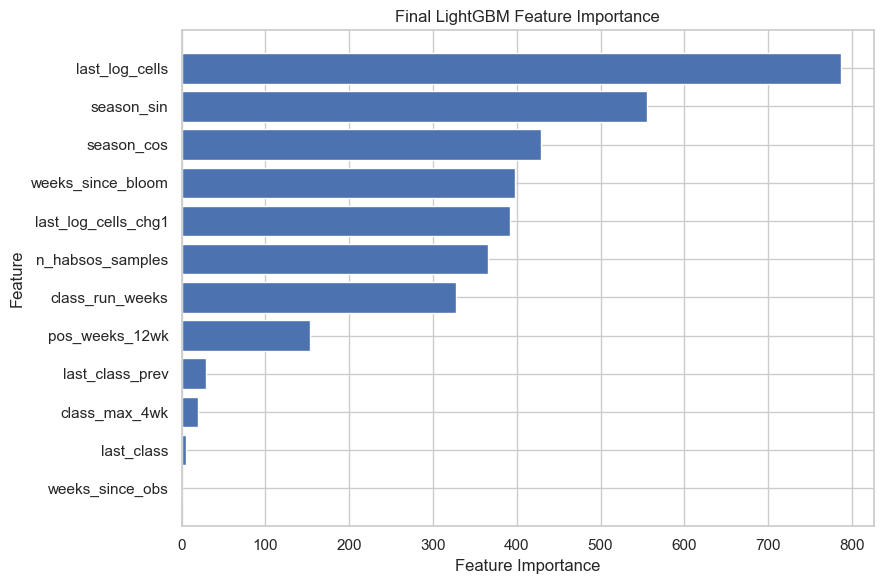

In [112]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Final LightGBM Feature Importance")

plt.tight_layout()
plt.show()

### LightGBM appears to rely most heavily on recent HAB history + seasonality.

That fits what we've already seen in my experiments: adding temperature, chlorophyll, wind, nutrients, and rainfall did not improve the 2024 validation results. The strongest information was already contained in the history-based core features.

In [113]:
gain_importance = pd.DataFrame({
    "Feature": regional_core,
    "Gain": final_lgbm.booster_.feature_importance(
        importance_type="gain"
    )
})

gain_importance = gain_importance.sort_values(
    "Gain",
    ascending=False
).reset_index(drop=True)

gain_importance["Gain_Percent"] = (
    gain_importance["Gain"]
    / gain_importance["Gain"].sum()
    * 100
).round(2)

gain_importance

,Feature,Gain,Gain_Percent
0,last_log_cells,5509.513282,46.83
1,weeks_since_bloom,2593.130438,22.04
2,last_log_cells_chg1,957.713955,8.14
3,season_cos,752.264019,6.39
4,season_sin,716.666393,6.09
5,n_habsos_samples,461.686797,3.92
6,class_run_weeks,361.427739,3.07
7,pos_weeks_12wk,197.616293,1.68
8,last_class_prev,162.205451,1.38
9,class_max_4wk,53.382100,0.45


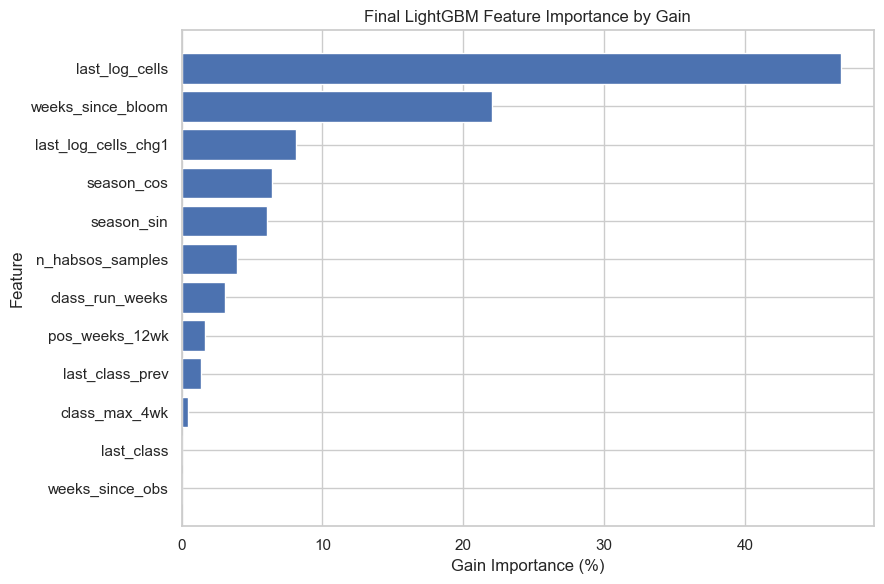

In [114]:
plt.figure(figsize=(9, 6))

plt.barh(
    gain_importance["Feature"],
    gain_importance["Gain_Percent"]
)

plt.gca().invert_yaxis()

plt.xlabel("Gain Importance (%)")
plt.ylabel("Feature")
plt.title("Final LightGBM Feature Importance by Gain")

plt.tight_layout()
plt.show()

### Feature Importance Interpretation

Gain-based feature importance showed that the final LightGBM model relied
primarily on recent HAB history.

`last_log_cells` was the strongest predictor, contributing approximately
46.8% of total model gain, followed by `weeks_since_bloom` at 22.0%.
Together, these two variables accounted for nearly 69% of the model's
gain.

Changes in recent cell counts (`last_log_cells_chg1`) contributed another
8.1%, while the seasonal features `season_sin` and `season_cos` together
contributed approximately 12.5%.

Overall, the results suggest that recent HAB magnitude, bloom persistence,
and seasonal timing were more useful to the LightGBM model than the
additional environmental feature groups tested.

Feature importance describes how the model used predictors and should not
be interpreted as evidence of causation.

## 12. Save Final Model and Results

The final LightGBM model, predictions, evaluation metrics, feature
importance, and model configuration are saved so the results can be
reproduced and shared with the team.


In [115]:
from pathlib import Path

# If notebook is running from models/boosting_mohammed/
RESULTS_DIR = Path("results")
FIGURES_DIR = Path("figures")
MODEL_DIR = Path("saved_model")

RESULTS_DIR.mkdir(exist_ok=True)
FIGURES_DIR.mkdir(exist_ok=True)
MODEL_DIR.mkdir(exist_ok=True)

print("Output folders ready!")

Output folders ready!


In [116]:
experiment_results = pd.DataFrame([
    {
        "Model": "Persistence Baseline",
        "Feature_Set": "last_class only",
        "Validation_Accuracy": 0.846,
        "Validation_Balanced_Accuracy": 0.613,
        "Validation_Macro_F1": 0.622
    },
    {
        "Model": "LightGBM Core",
        "Feature_Set": "regional_core",
        "Validation_Accuracy": 0.846,
        "Validation_Balanced_Accuracy": 0.728,
        "Validation_Macro_F1": 0.698
    },
    {
        "Model": "LightGBM Core Balanced",
        "Feature_Set": "regional_core",
        "Validation_Accuracy": 0.865,
        "Validation_Balanced_Accuracy": 0.737,
        "Validation_Macro_F1": 0.715
    },
    {
        "Model": "LightGBM Core + Temperature",
        "Feature_Set": "core + temperature",
        "Validation_Accuracy": 0.808,
        "Validation_Balanced_Accuracy": 0.624,
        "Validation_Macro_F1": 0.615
    },
    {
        "Model": "LightGBM Core + Chlorophyll",
        "Feature_Set": "core + chlorophyll",
        "Validation_Accuracy": 0.769,
        "Validation_Balanced_Accuracy": 0.665,
        "Validation_Macro_F1": 0.638
    },
    {
        "Model": "LightGBM Core + Wind",
        "Feature_Set": "core + wind",
        "Validation_Accuracy": 0.808,
        "Validation_Balanced_Accuracy": 0.710,
        "Validation_Macro_F1": 0.670
    },
    {
        "Model": "LightGBM Core + Nutrients",
        "Feature_Set": "core + nutrients",
        "Validation_Accuracy": 0.827,
        "Validation_Balanced_Accuracy": 0.661,
        "Validation_Macro_F1": 0.648
    },
    {
        "Model": "LightGBM Core + Rain",
        "Feature_Set": "core + rain",
        "Validation_Accuracy": 0.827,
        "Validation_Balanced_Accuracy": 0.691,
        "Validation_Macro_F1": 0.673
    },
    {
        "Model": "LightGBM Clean Major Features",
        "Feature_Set": "core + temperature + nutrients + rain",
        "Validation_Accuracy": 0.788,
        "Validation_Balanced_Accuracy": 0.615,
        "Validation_Macro_F1": 0.604
    },
    {
        "Model": "Tuned LightGBM Core Balanced",
        "Feature_Set": "regional_core",
        "Validation_Accuracy": 0.865,
        "Validation_Balanced_Accuracy": 0.737,
        "Validation_Macro_F1": 0.717
    }
])

experiment_results.to_csv(
    RESULTS_DIR / "experiment_results.csv",
    index=False
)

experiment_results

,Model,Feature_Set,Validation_Accuracy,Validation_Balanced_Accuracy,Validation_Macro_F1
0,Persistence Baseline,last_class only,0.846,0.613,0.622
1,LightGBM Core,regional_core,0.846,0.728,0.698
2,LightGBM Core Balanced,regional_core,0.865,0.737,0.715
3,LightGBM Core + Temperature,core + temperature,0.808,0.624,0.615
4,LightGBM Core + Chlorophyll,core + chlorophyll,0.769,0.665,0.638
5,LightGBM Core + Wind,core + wind,0.808,0.710,0.670
6,LightGBM Core + Nutrients,core + nutrients,0.827,0.661,0.648
7,LightGBM Core + Rain,core + rain,0.827,0.691,0.673
8,LightGBM Clean Major Features,core + temperature + nutrients + rain,0.788,0.615,0.604
9,Tuned LightGBM Core Balanced,regional_core,0.865,0.737,0.717


In [117]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Macro metrics - each class counts equally
test_precision_macro = precision_score(
    y_test,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_recall_macro = recall_score(
    y_test,
    y_test_pred,
    average="macro",
    zero_division=0
)

test_f1_macro = f1_score(
    y_test,
    y_test_pred,
    average="macro",
    zero_division=0
)

# Weighted metrics - accounts for number of examples in each class
test_precision_weighted = precision_score(
    y_test,
    y_test_pred,
    average="weighted",
    zero_division=0
)

test_recall_weighted = recall_score(
    y_test,
    y_test_pred,
    average="weighted",
    zero_division=0
)

test_f1_weighted = f1_score(
    y_test,
    y_test_pred,
    average="weighted",
    zero_division=0
)

# Save final test metrics
final_test_metrics = pd.DataFrame([{
    "Model": "Final Tuned LightGBM",
    "Test_Year": 2025,

    "Accuracy": test_accuracy,
    "Balanced_Accuracy": test_balanced_accuracy,

    "Precision_Weighted": test_precision_weighted,
    "Recall_Weighted": test_recall_weighted,
    "F1_Weighted": test_f1_weighted,

    "Precision_Macro": test_precision_macro,
    "Recall_Macro": test_recall_macro,
    "F1_Macro": test_f1_macro,

    "Test_Rows": len(y_test)
}])

final_test_metrics.to_csv(
    RESULTS_DIR / "final_test_metrics.csv",
    index=False
)

final_test_metrics

,Model,Test_Year,Accuracy,Balanced_Accuracy,Precision_Weighted,Recall_Weighted,F1_Weighted,Precision_Macro,Recall_Macro,F1_Macro,Test_Rows
0,Final Tuned LightGBM,2025,0.903846,0.588889,0.961538,0.903846,0.931698,0.611111,0.588889,0.599617,52


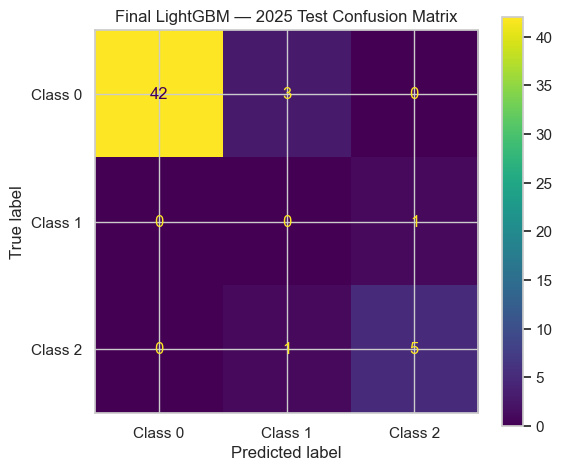

In [118]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=["Class 0", "Class 1", "Class 2"]
)

disp.plot(
    ax=ax,
    values_format="d"
)

plt.title("Final LightGBM — 2025 Test Confusion Matrix")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

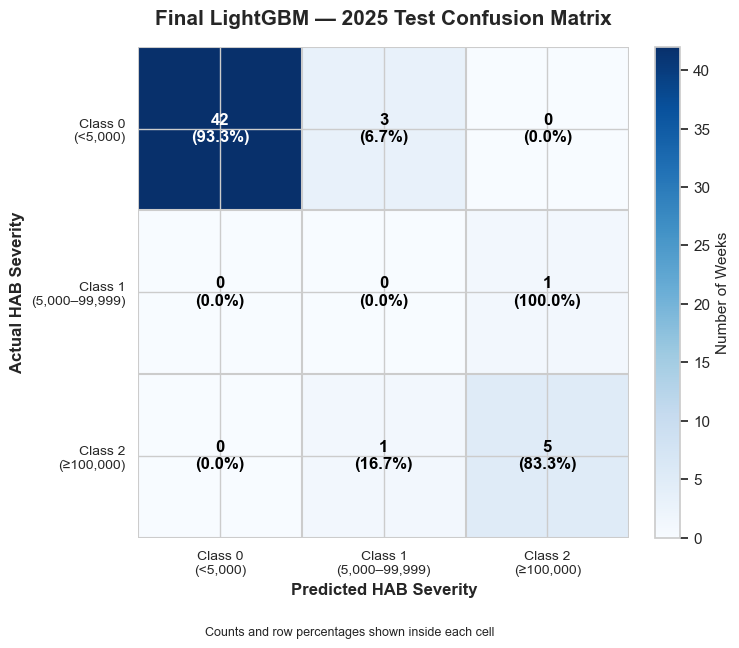

In [119]:
import numpy as np
import matplotlib.pyplot as plt

# Class labels
class_labels = [
    "Class 0\n(<5,000)",
    "Class 1\n(5,000–99,999)",
    "Class 2\n(≥100,000)"
]

# Convert each row to percentages
cm_percent = cm_test.astype(float) / cm_test.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(8, 6.5))

# Draw matrix
im = ax.imshow(cm_test, cmap="Blues")

# Color bar
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Number of Weeks", fontsize=11)

# Axis labels
ax.set_xticks(np.arange(len(class_labels)))
ax.set_yticks(np.arange(len(class_labels)))

ax.set_xticklabels(class_labels, fontsize=10)
ax.set_yticklabels(class_labels, fontsize=10)

ax.set_xlabel("Predicted HAB Severity", fontsize=12, fontweight="bold")
ax.set_ylabel("Actual HAB Severity", fontsize=12, fontweight="bold")

# Title
ax.set_title(
    "Final LightGBM — 2025 Test Confusion Matrix",
    fontsize=15,
    fontweight="bold",
    pad=16
)

# Add count + percentage inside each cell
threshold = cm_test.max() / 2

for i in range(cm_test.shape[0]):
    for j in range(cm_test.shape[1]):

        count = cm_test[i, j]
        percent = cm_percent[i, j]

        text_color = "white" if count > threshold else "black"

        ax.text(
            j,
            i,
            f"{count}\n({percent:.1f}%)",
            ha="center",
            va="center",
            fontsize=12,
            fontweight="bold",
            color=text_color
        )

# Remove unnecessary borders
for spine in ax.spines.values():
    spine.set_visible(False)

# Add light grid between cells
ax.set_xticks(np.arange(-0.5, len(class_labels), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(class_labels), 1), minor=True)

ax.grid(
    which="minor",
    linewidth=1.5
)

ax.tick_params(which="minor", bottom=False, left=False)

# Small note at bottom
fig.text(
    0.5,
    0.01,
    "Counts and row percentages shown inside each cell",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Save high-quality figure
plt.savefig(
    FIGURES_DIR / "final_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Save the final model

In [120]:
import joblib
from pathlib import Path

MODEL_DIR = Path("saved_model")
MODEL_DIR.mkdir(exist_ok=True)

# Save the complete sklearn-style LightGBM model
joblib.dump(
    final_lgbm,
    MODEL_DIR / "final_lightgbm_model.pkl"
)

print("Saved final_lightgbm_model.pkl")

Saved final_lightgbm_model.pkl


In [121]:
final_lgbm.booster_.save_model(
    MODEL_DIR / "final_lightgbm_model.txt"
)

print("Saved final_lightgbm_model.txt")

Saved final_lightgbm_model.txt


In [122]:
loaded_model = joblib.load(
    MODEL_DIR / "final_lightgbm_model.pkl"
)

loaded_predictions = loaded_model.predict(X_test)

print(
    "Predictions match:",
    np.array_equal(
        loaded_predictions,
        y_test_pred
    )
)

Predictions match: True
